# SOFR Short-Rate Modelling with a Partitioning Approach

Replication of **Orlando, Mininni & Bufalo** — [*"Forecasting interest rates through Vasicek and CIR models:
a partitioning approach"*](https://arxiv.org/abs/1901.02246) — applied to the **Secured Overnight Financing Rate (SOFR)**.

Instead of calibrating one Vasicek / CIR model to the whole history, the series is split into
**statistically homogeneous chunks** (windows whose rates pass a distributional test), and each chunk
gets its own parameters $(\kappa, \theta, \sigma)$. The two models are then compared on in-sample
one-step-ahead fit.

**Contents**
1. [Data — weekly SOFR from FRED](#1.-Data)
2. [Partitioning by normality (Lilliefors)](#2.-Partitioning-by-normality-(Lilliefors))
3. [Calibration — Bibby estimating functions](#3.-Calibration)
4. [In-sample fitted rates](#4.-In-sample-fitted-rates)
5. [Error analysis](#5.-Error-analysis)
6. [Partitioning by non-central $\chi^2$ (work in progress)](#6.-Partitioning-by-non-central-chi-squared-(work-in-progress))

In [1]:
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas_datareader.data as web
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors

## 1. Data

Daily overnight SOFR from FRED (series `SOFR`, available from 2018-04-03). Rates are in percent.

In [2]:
def get_sofr(start="2018-04-03", end=None):
    """Daily SOFR from FRED. Series starts 2018-04-03."""
    end = end or datetime.today().strftime("%Y-%m-%d")
    df = web.DataReader("SOFR", "fred", start, end)
    return df.rename(columns={"SOFR": "sofr"}).dropna()


daily_df = get_sofr(start="2020-01-01", end="2026-01-01")
daily_df.head()

,sofr
DATE,
2020-01-02,1.54
2020-01-03,1.55
2020-01-06,1.55
2020-01-07,1.56
2020-01-08,1.55


### Weekly sampling

The paper works with weekly observations ($\Delta t$ = 1 week). Each daily observation is tagged with its
ISO week, and the **last available trading day of each week** is kept — this handles holiday weeks
without forward-filling.

In [3]:
iso = daily_df.index.isocalendar()
daily_df["week_year"] = iso.year.astype(str) + "-W" + iso.week.astype(str).str.zfill(2)
daily_df["week_day"] = daily_df.index.day_name()

# row_number == 1 marks the last trading day within each ISO week
daily_df["row_number"] = daily_df.groupby("week_year").cumcount(ascending=False) + 1
week_df = daily_df[daily_df["row_number"] == 1].copy()

week_df.head()

,sofr,week_year,week_day,row_number
DATE,,,,
2020-01-03,1.55,2020-W01,Friday,1
2020-01-10,1.55,2020-W02,Friday,1
2020-01-17,1.54,2020-W03,Friday,1
2020-01-24,1.53,2020-W04,Friday,1
2020-01-31,1.60,2020-W05,Friday,1


In [4]:
week_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 314 entries, 2020-01-03 to 2025-12-31
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   sofr        314 non-null    float64
 1   week_year   314 non-null    str    
 2   week_day    314 non-null    str    
 3   row_number  314 non-null    int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 12.3 KB


## 2. Partitioning by normality (Lilliefors)

**Algorithm (forward-expanding windows).** Starting at index `start`, take the first `min_points`
observations and test them for normality with the Lilliefors test. While the test passes
($p \ge \alpha$), extend the window by one observation. When it fails, close the chunk at the last
passing end point and start the next chunk there. If even the minimum window fails, it is closed at
`min_points` so the loop always advances. A tail shorter than `min_points` is left unassigned (`-1`).

**ZIRP guard.** During the 2020–22 zero-rate period SOFR barely moves, so windows are (near-)constant and
the test statistic is undefined. With `std_threshold` set, any window whose standard deviation is below
the threshold is treated as passing — there is nothing meaningful to test.

In [5]:
def partition_by_normality(week_df, rate_col="sofr", min_points=4, alpha=0.05, std_threshold=None):
    """Forward-expanding Lilliefors partitioning.

    std_threshold=None -> plain test on every window.
    std_threshold=x    -> windows with std < x are treated as passing (ZIRP guard).
    """
    rates = week_df[rate_col].values
    n = len(rates)
    chunk_ids = np.full(n, -1, dtype=int)  # -1 = unassigned (leftover tail)

    chunk_num, start = 0, 0
    while start < n:
        if n - start < min_points:
            break  # too few points left -> leave as tail

        end = start + min_points
        last_good_end = None

        while end <= n:
            window = rates[start:end]

            if std_threshold is not None and np.std(window) < std_threshold:
                passes = True  # near-degenerate window: nothing meaningful to test
            else:
                _, p_value = lilliefors(window, dist="norm")
                passes = p_value >= alpha

            if passes:
                last_good_end = end
                end += 1
            else:
                break

        if last_good_end is None:
            last_good_end = start + min_points  # force-close to avoid an infinite loop

        chunk_ids[start:last_good_end] = chunk_num
        chunk_num += 1
        start = last_good_end

    out = week_df.copy()
    out["chunk_id"] = chunk_ids
    return out

In [6]:
def plot_chunks(df, chunk_col="chunk_id", rate_col="sofr", ncols=4, figsize=(20, 30)):
    """Small-multiples plot: one panel per chunk, shared y-axis."""
    chunks = df[chunk_col].unique()
    nrows = int(np.ceil(len(chunks) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharey=True)

    for ax, cid in zip(axes.flatten(), chunks):
        group = df[df[chunk_col] == cid]
        ax.plot(group.index, group[rate_col])
        ax.set_title(f"Chunk {cid}")
        ax.grid(True, alpha=0.3)
        ax.tick_params(axis="x", rotation=45)

    fig.supxlabel("Date")
    fig.supylabel("SOFR (%)")
    plt.tight_layout()
    plt.show()

### 2a. Without the ZIRP guard

Constant windows make Lilliefors return NaN, which fails the test and force-closes chunks at
`min_points` — the zero-rate period shatters into many tiny chunks.

In [7]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)  # constant windows -> divide-by-zero inside lilliefors
    df_naive = partition_by_normality(week_df, "sofr", min_points=4, alpha=0.05, std_threshold=None)

df_naive["chunk_id"].nunique()

56

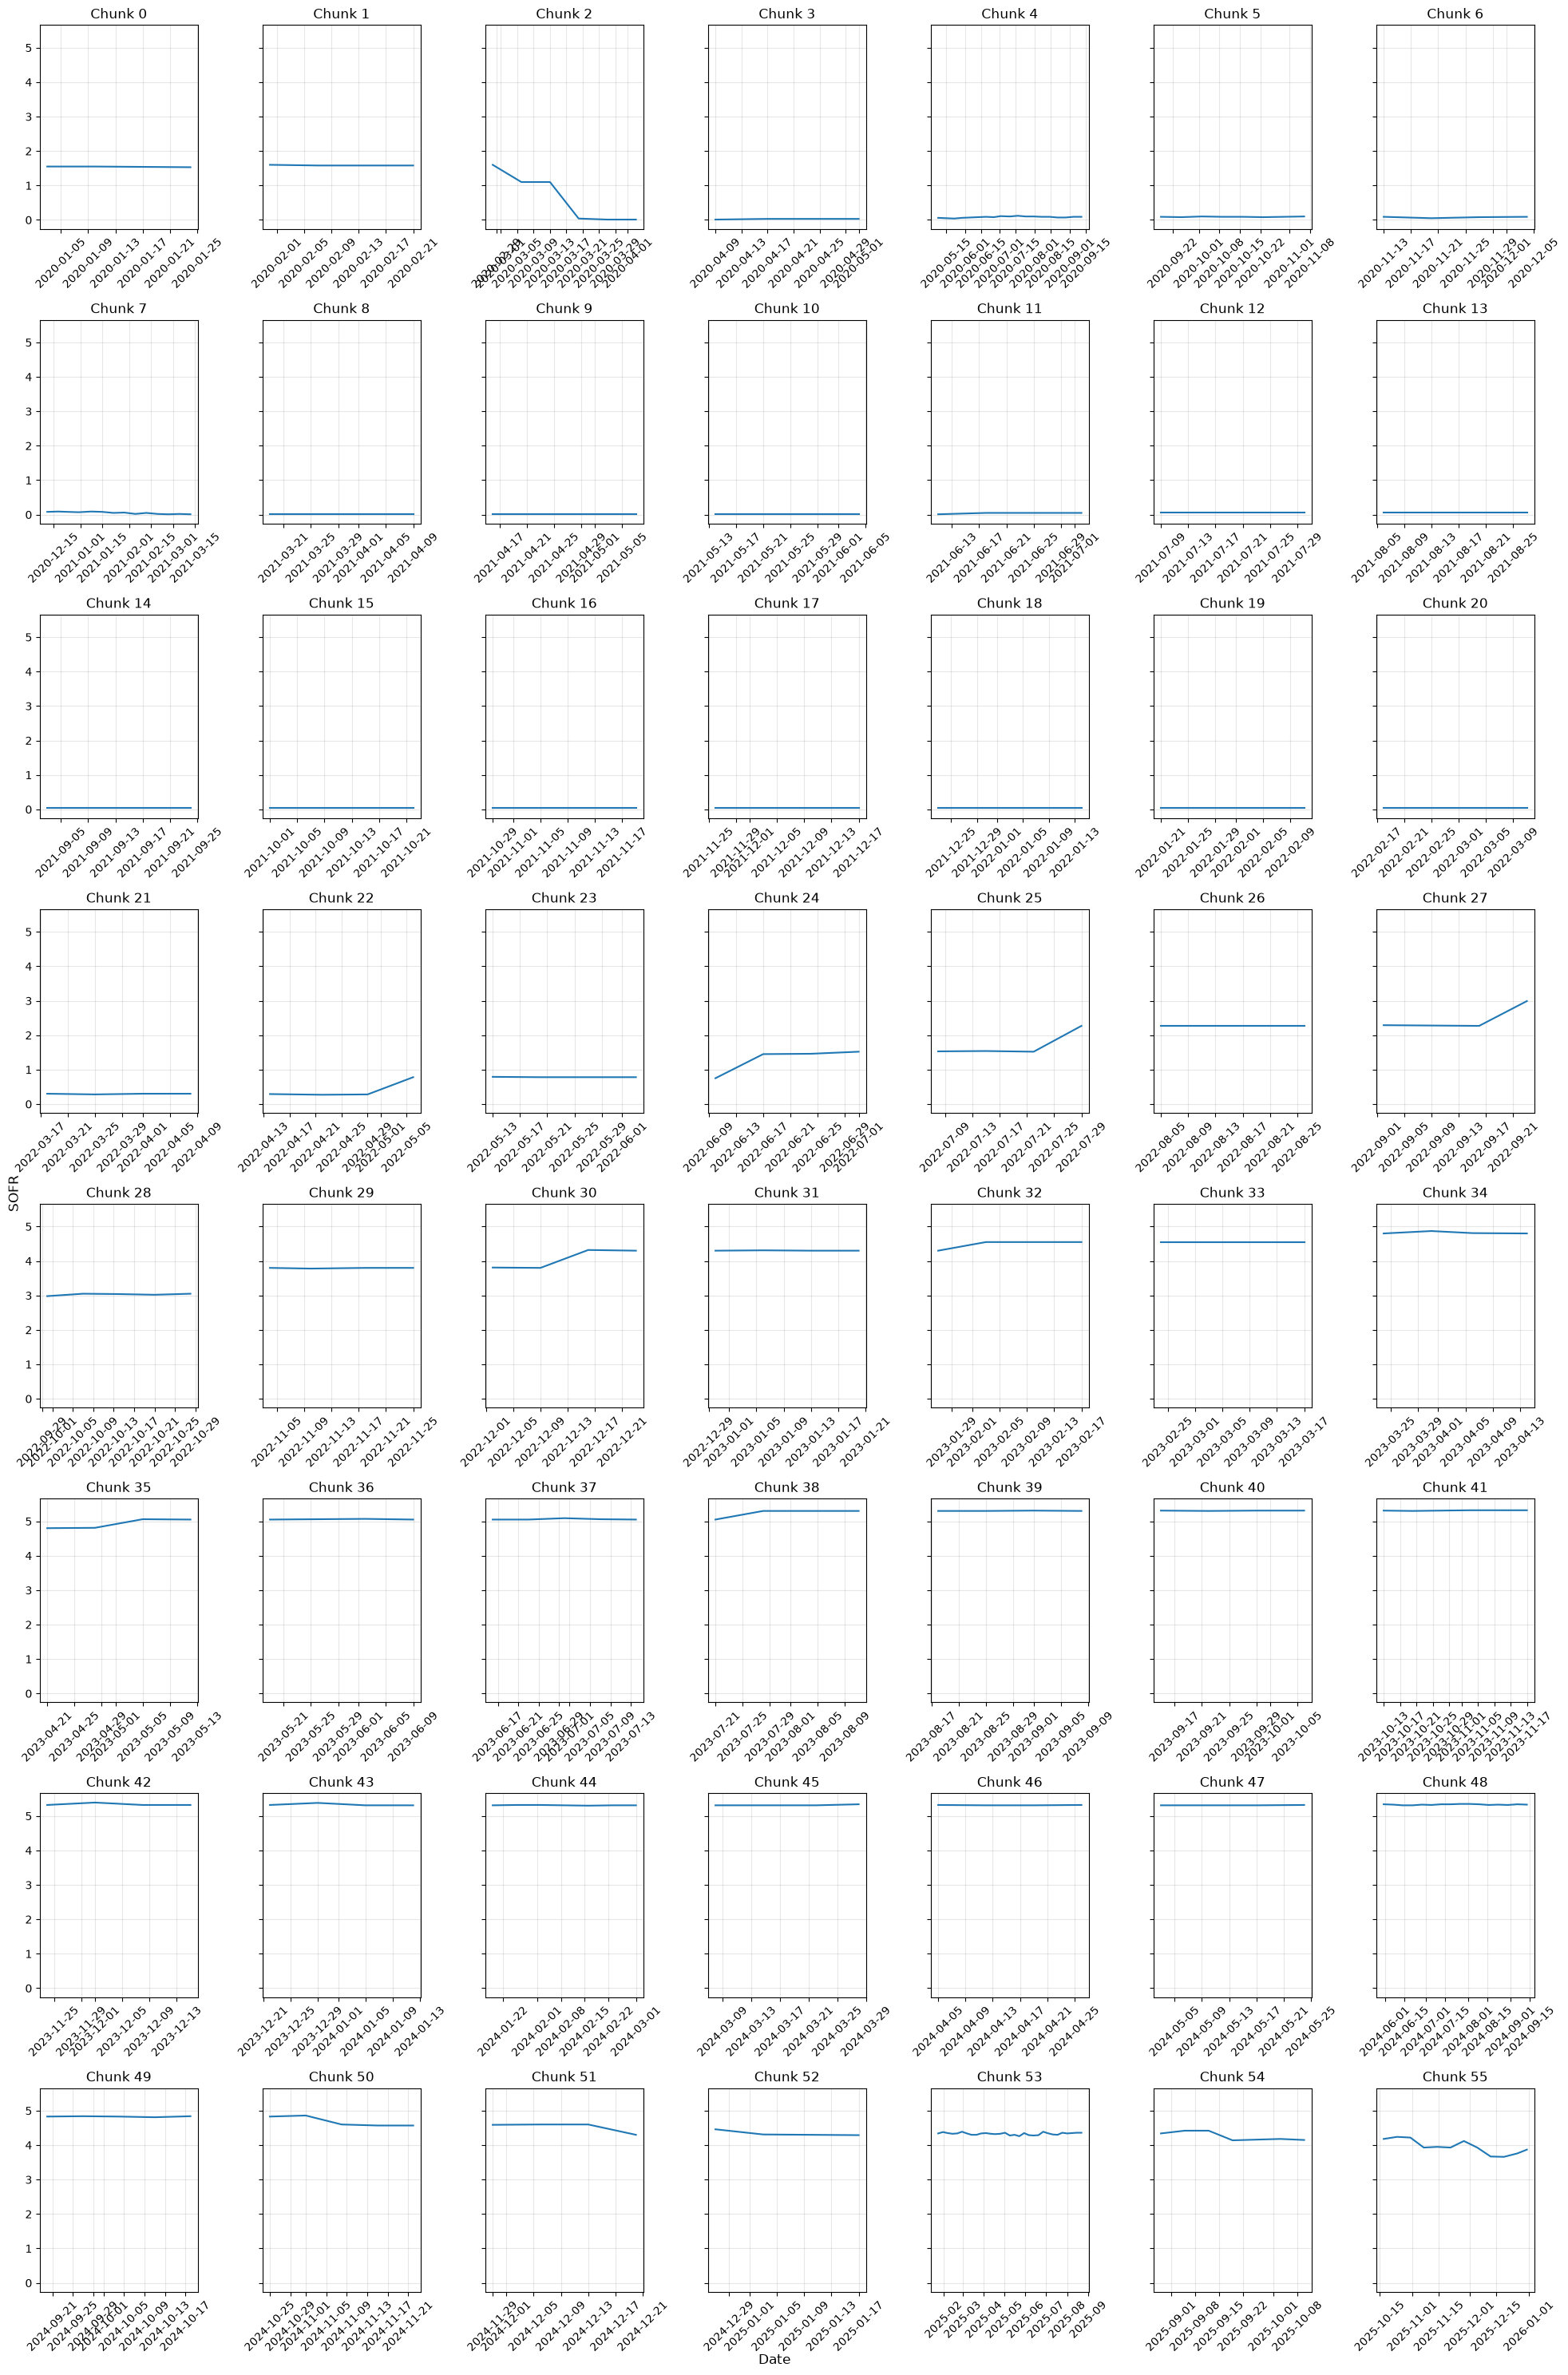

In [8]:
plot_chunks(df_naive, ncols=7)

### 2b. With the ZIRP guard (`std_threshold = 0.01`)

In [9]:
df_norm = partition_by_normality(week_df, "sofr", min_points=4, alpha=0.05, std_threshold=0.01)
df_norm["chunk_id"].nunique()

36

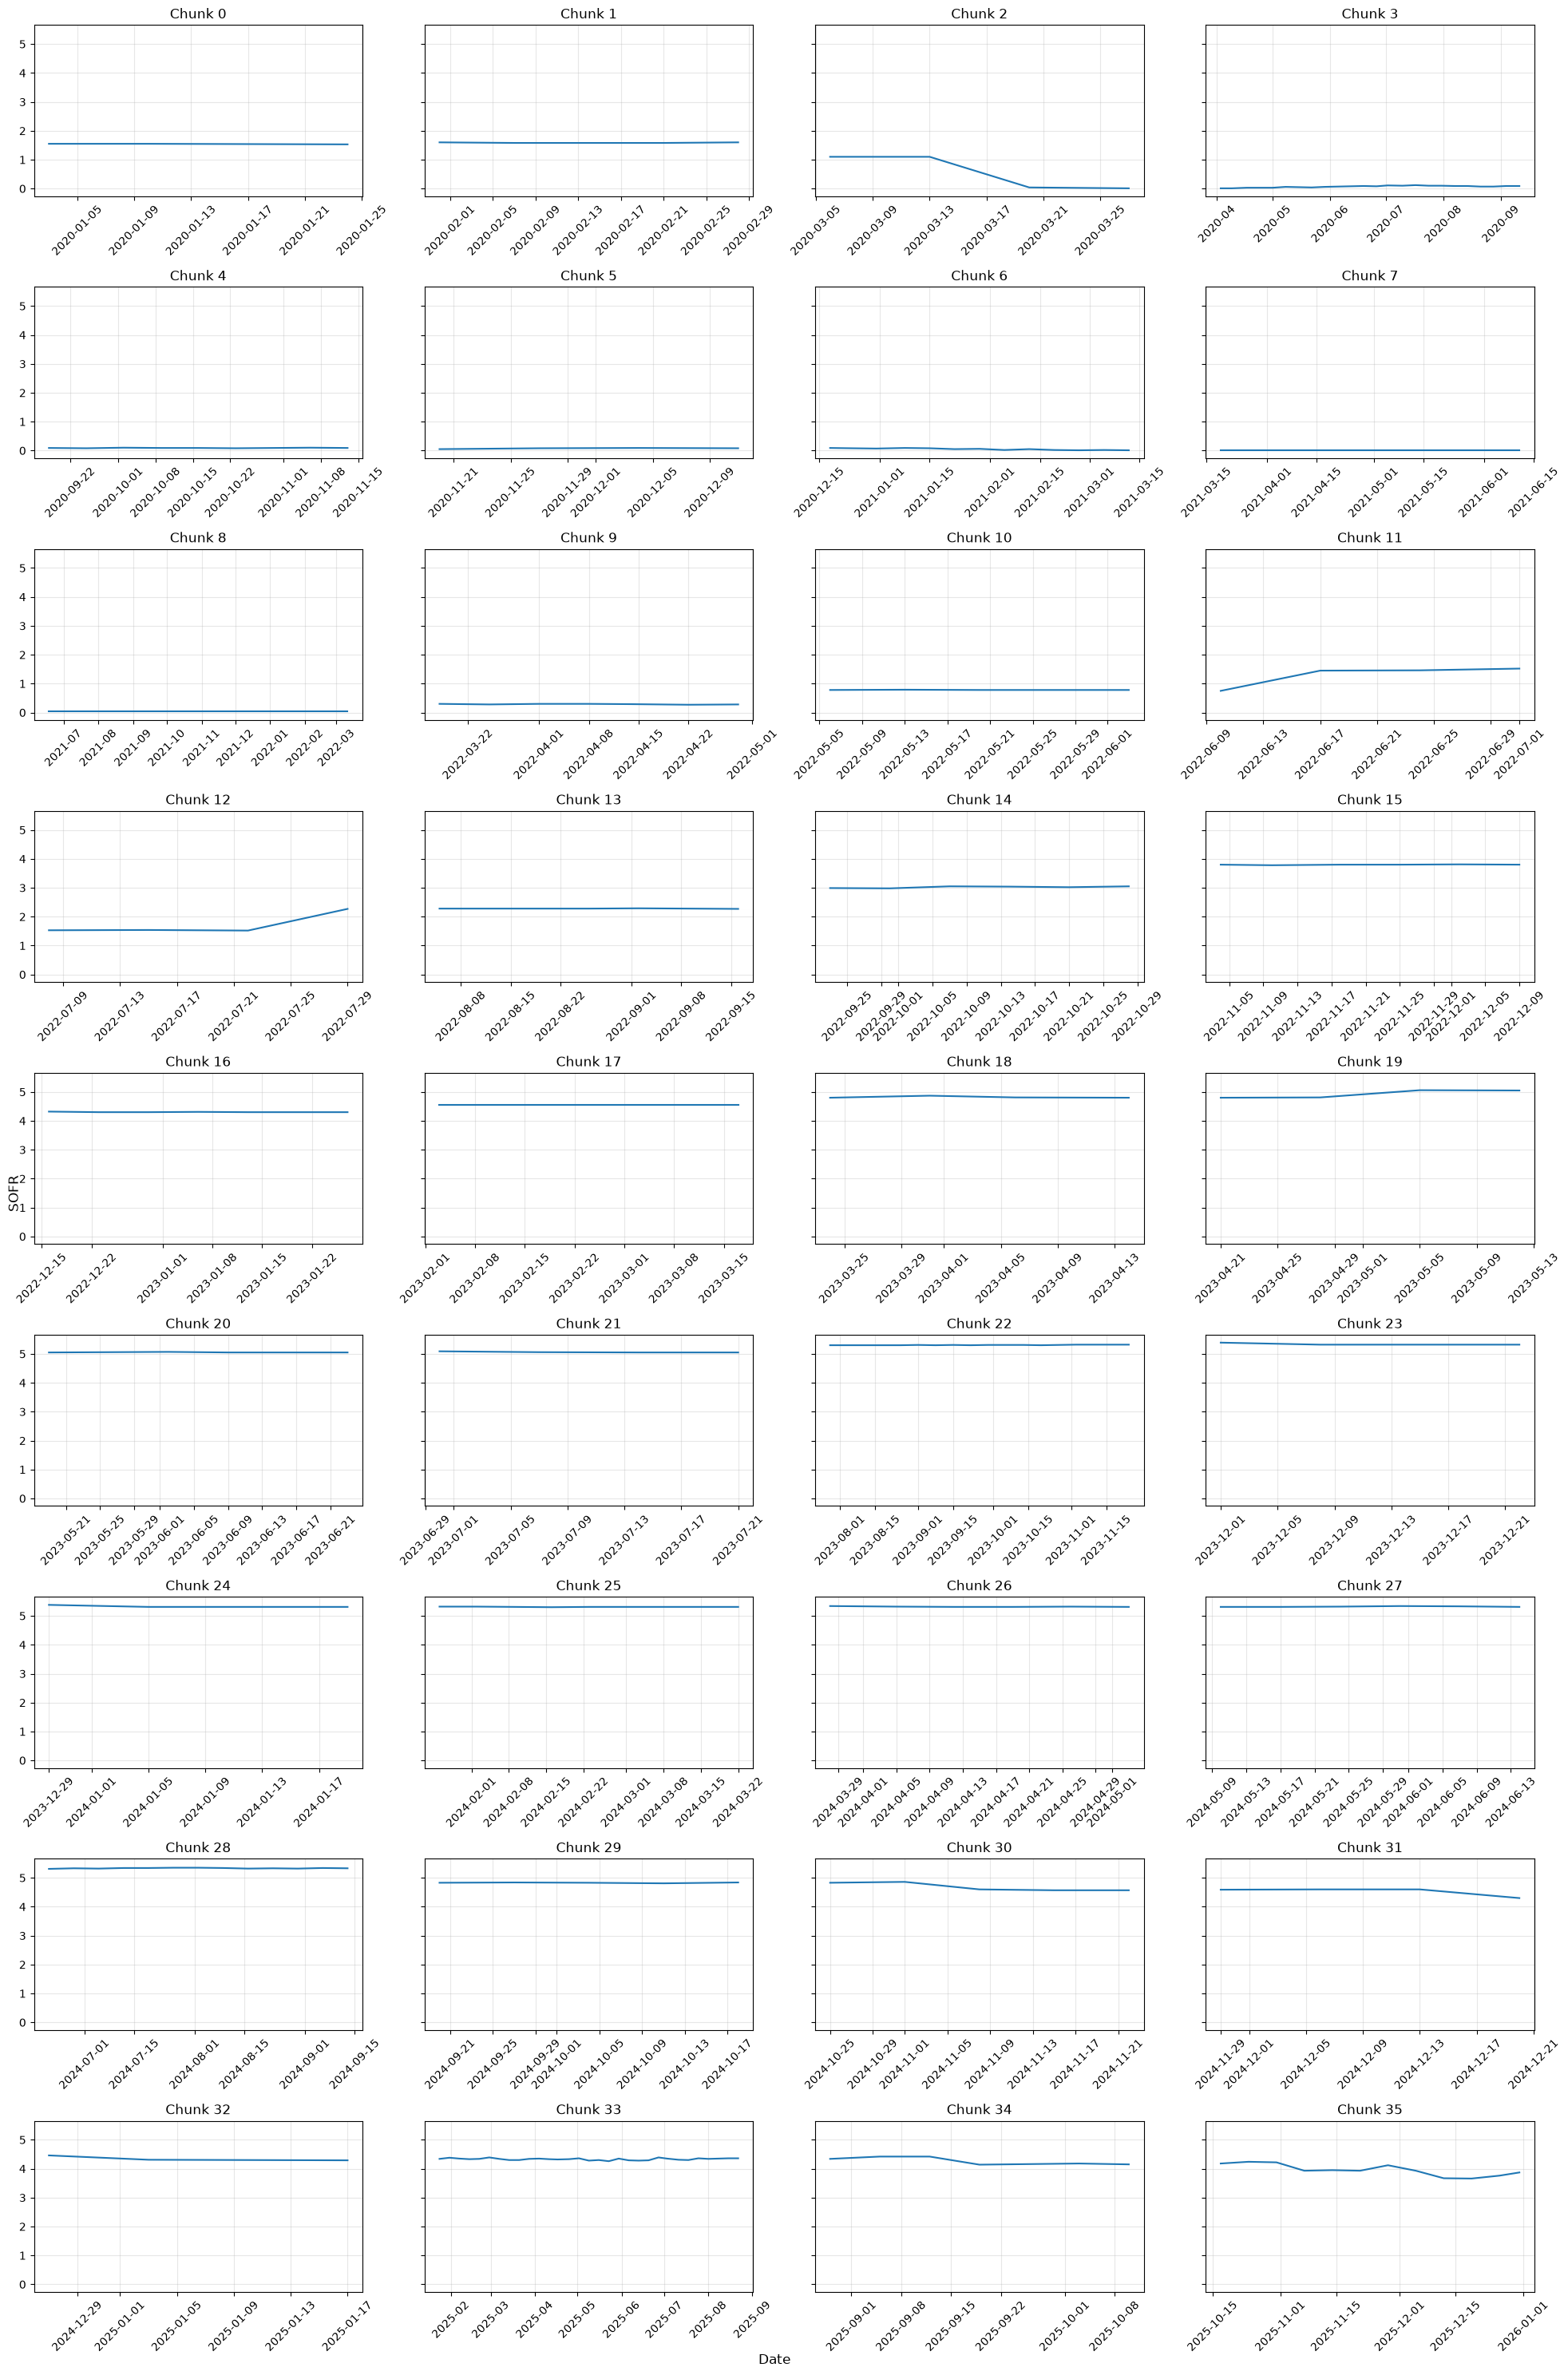

In [10]:
plot_chunks(df_norm, ncols=4)

In [11]:
df_norm["chunk_id"].value_counts()

chunk_id
8     39
33    31
3     24
22    18
6     13
7     13
28    13
35    12
4      9
25     9
9      7
13     7
16     7
17     7
34     7
14     6
15     6
20     6
26     6
27     6
1      5
10     5
29     5
30     5
0      4
2      4
5      4
11     4
12     4
18     4
19     4
21     4
23     4
24     4
31     4
32     4
Name: count, dtype: int64

### 2c. Merging small chunks

Many chunks still have 4–7 points, too few for stable estimation. Chunks are walked chronologically
and any group smaller than `min_size = 12` keeps absorbing the following chunks until it clears the
threshold. If the very first group is still too small, it is folded forward into the second.

In [12]:
def merge_small_chunks(df, chunk_col="chunk_id", min_size=12):
    """Forward-chain chunks so every merged group has at least `min_size` points."""
    df = df.copy()
    original_ids = df[chunk_col].values
    unique_ids_in_order = pd.unique(original_ids[original_ids != -1])  # skip leftover tail
    sizes = {cid: np.sum(original_ids == cid) for cid in unique_ids_in_order}

    groups, current_group, current_size = [], [], 0
    for cid in unique_ids_in_order:
        if current_size < min_size and current_group:
            # still-open small group -> keep absorbing forward
            current_group.append(cid)
            current_size += sizes[cid]
        else:
            if current_group:
                groups.append(current_group)
            current_group, current_size = [cid], sizes[cid]

    if current_group:
        groups.append(current_group)

    # A too-small first group has nothing behind it -> fold it forward instead
    if len(groups) > 1 and sum(sizes[c] for c in groups[0]) < min_size:
        groups = [groups[0] + groups[1]] + groups[2:]

    id_map = {old: new for new, group in enumerate(groups) for old in group}
    df[chunk_col] = df[chunk_col].map(lambda x: id_map.get(x, -1))
    return df

In [13]:
df_norm = merge_small_chunks(df_norm, chunk_col="chunk_id", min_size=12)
print(df_norm["chunk_id"].value_counts().sort_index())

chunk_id
0     13
1     24
2     13
3     13
4     13
5     39
6     12
7     15
8     12
9     14
10    14
11    22
12    17
13    12
14    13
15    14
16    35
17    19
Name: count, dtype: int64


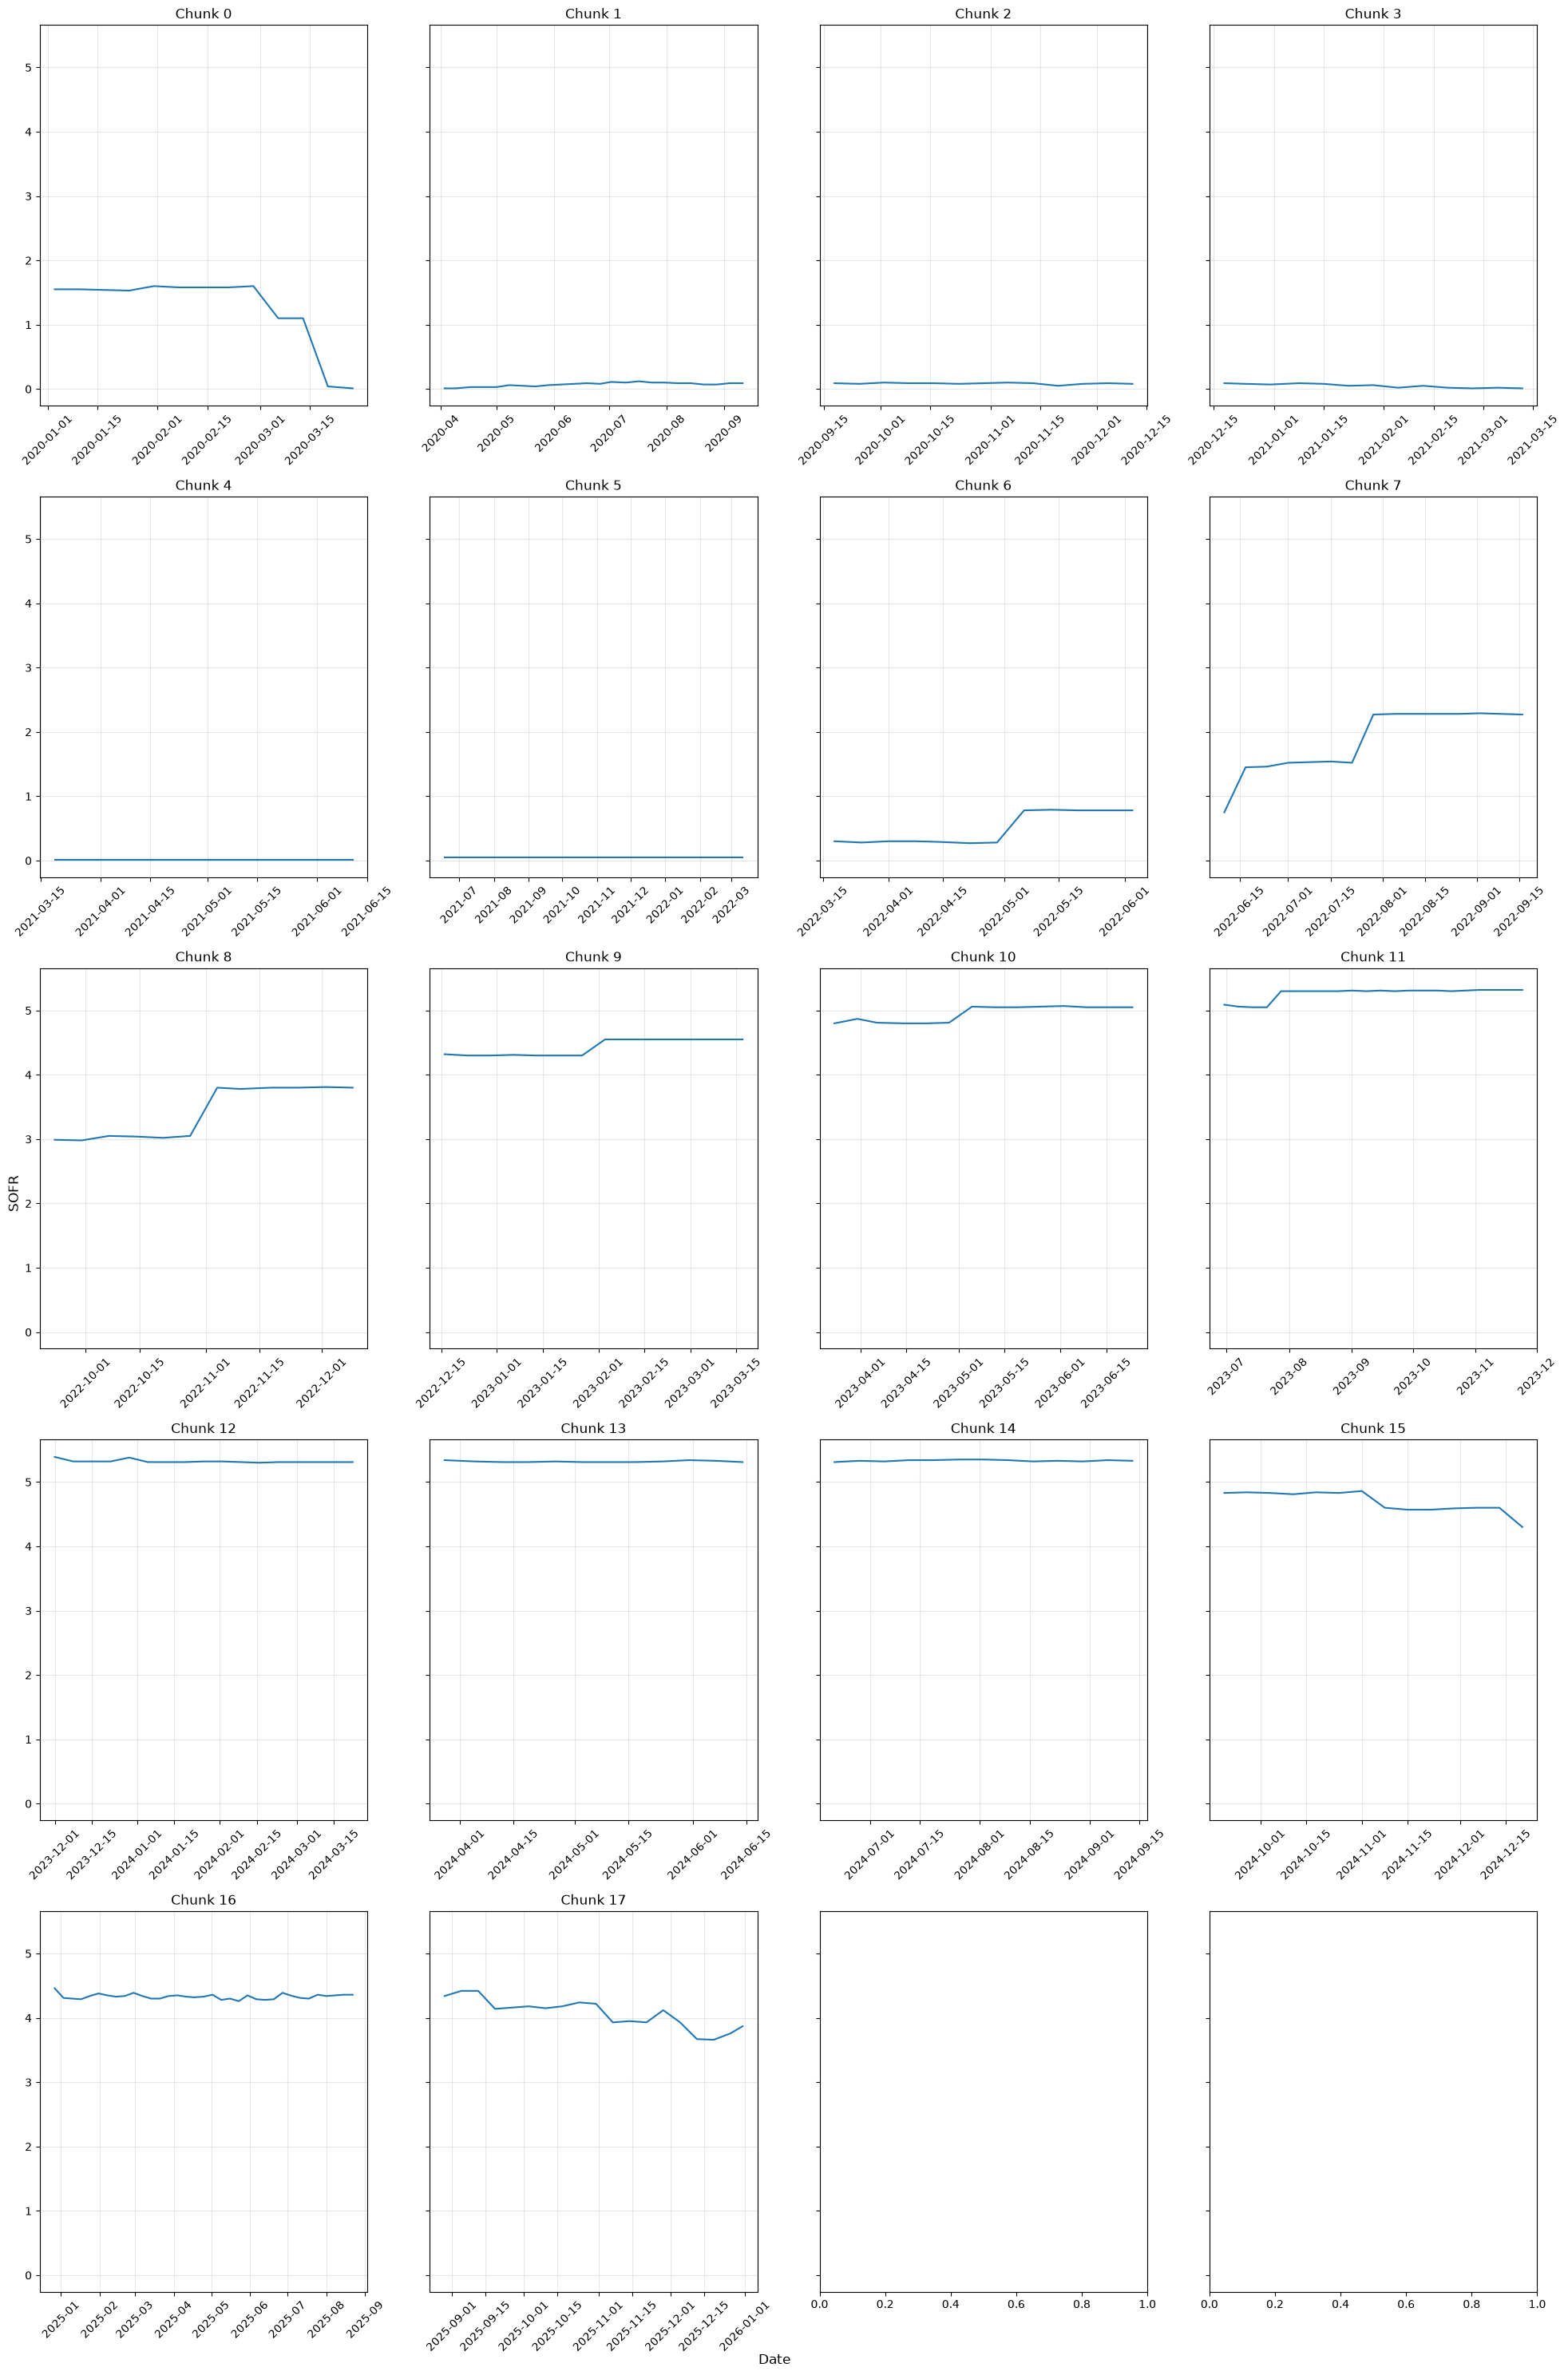

In [14]:
plot_chunks(df_norm, ncols=4)

## 3. Calibration

Both models are calibrated chunk-by-chunk with the closed-form **estimating-function estimators of
Bibby et al.** (paper eqs. 5–6), with $\Delta t = 1$ week.

| Model | Dynamics |
|---|---|
| Vasicek | $dr_t = \kappa(\theta - r_t)\,dt + \sigma\,dW_t$ |
| CIR | $dr_t = \kappa(\theta - r_t)\,dt + \sigma\sqrt{r_t}\,dW_t$ |

Writing $m = n-1$ and using lagged pairs $(r_{i-1}, r_i)$, the Vasicek estimators are

$$
\hat\kappa = -\ln\frac{\frac{1}{m}\sum r_{i-1}\sum r_i - \sum r_{i-1}r_i}{\frac{1}{m}\left(\sum r_{i-1}\right)^2 - \sum r_{i-1}^2},
\qquad
\hat\theta = \frac{1}{1-e^{-\hat\kappa}}\left(\frac{1}{m}\sum r_i - e^{-\hat\kappa}\frac{1}{m}\sum r_{i-1}\right),
$$

$$
\hat\sigma^2 = \frac{2\hat\kappa}{1-e^{-2\hat\kappa}}\cdot\frac{1}{m}\sum\left(r_i - r_{i-1}e^{-\hat\kappa} - \hat\theta(1-e^{-\hat\kappa})\right)^2 .
$$

The CIR estimators follow the same idea, weighted by $1/r_{i-1}$ (see `calibrate_cir`).

In [15]:
def calibrate_vasicek(r):
    """Bibby et al. estimating-function estimators for Vasicek (paper eq. 6)."""
    r = np.asarray(r, dtype=float)
    r_lag, r_cur = r[:-1], r[1:]
    m = len(r) - 1

    sum_lag, sum_cur = r_lag.sum(), r_cur.sum()
    sum_lag_cur = (r_lag * r_cur).sum()
    sum_lag_sq = (r_lag ** 2).sum()

    num = (sum_lag / m) * sum_cur - sum_lag_cur
    den = (sum_lag / m) ** 2 * m - sum_lag_sq
    kappa = -np.log(num / den)

    theta = (1 / (1 - np.exp(-kappa))) * (sum_cur / m - np.exp(-kappa) * sum_lag / m)

    resid = r_cur - r_lag * np.exp(-kappa) - theta * (1 - np.exp(-kappa))
    sigma2 = (2 * kappa / (1 - np.exp(-2 * kappa))) * (resid ** 2).sum() / m

    return kappa, theta, np.sqrt(sigma2)

In [16]:
def calibrate_cir(r):
    """Bibby et al. estimating-function estimators for CIR (paper eq. 5). Requires r > 0."""
    r = np.asarray(r, dtype=float)
    r_lag, r_cur = r[:-1], r[1:]
    inv_lag = 1.0 / r_lag
    m = len(r) - 1

    kappa = -np.log(
        (m * (r_cur / r_lag).sum() - r_cur.sum() * inv_lag.sum())
        / (m ** 2 - r_lag.sum() * inv_lag.sum())
    )

    theta = (r_cur.sum() / m) + (np.exp(-kappa) / (m * (1 - np.exp(-kappa)))) * (r[-1] - r[0])

    num = (inv_lag * (r_cur - r_lag * np.exp(-kappa) - theta * (1 - np.exp(-kappa))) ** 2).sum()
    den = (inv_lag * ((theta / 2 - r_lag) * np.exp(-2 * kappa)
                      - (theta - r_lag) * np.exp(-kappa)
                      + theta / 2) / kappa).sum()
    sigma2 = num / den

    return kappa, theta, np.sqrt(sigma2)

In [17]:
def calibrate_all_chunks(df, chunk_col="chunk_id", rate_col="sofr"):
    """Calibrate Vasicek and CIR on every chunk. Degenerate chunks yield NaN / inf parameters."""
    results = []
    for cid, group in df.groupby(chunk_col):
        rates = group[rate_col].values

        # Constant (ZIRP) chunks produce 0/0 inside the estimators -> silence and keep the NaN/inf
        with np.errstate(divide="ignore", invalid="ignore"):
            try:
                k_v, theta_v, sigma_v = calibrate_vasicek(rates)
            except Exception:
                k_v, theta_v, sigma_v = np.nan, np.nan, np.nan
            try:
                k_c, theta_c, sigma_c = calibrate_cir(rates)
            except Exception:
                k_c, theta_c, sigma_c = np.nan, np.nan, np.nan

        results.append({
            "chunk_id": cid,
            "n_points": len(rates),
            "start_date": group.index.min(),
            "end_date": group.index.max(),
            "kappa_vasicek": k_v, "theta_vasicek": theta_v, "sigma_vasicek": sigma_v,
            "kappa_cir": k_c, "theta_cir": theta_c, "sigma_cir": sigma_c,
        })
    return pd.DataFrame(results)

In [18]:
results = calibrate_all_chunks(df_norm, "chunk_id", "sofr")
results

,chunk_id,n_points,start_date,end_date,kappa_vasicek,theta_vasicek,sigma_vasicek,kappa_cir,theta_cir,sigma_cir
0,0,13,2020-01-03,2020-03-27,-0.087155,2.771732,0.297970,0.069915,-0.537981,0.316847
1,1,24,2020-04-03,2020-09-11,0.199817,0.087900,0.014521,0.143474,0.094720,0.061851
2,2,13,2020-09-18,2020-12-11,3.633191,0.084977,0.033919,2.888518,0.084951,0.101111
3,3,13,2020-12-18,2021-03-12,0.289984,0.026849,0.021615,0.387168,0.032566,0.112902
4,4,13,2021-03-19,2021-06-11,-0.000000,NaN,NaN,-0.000000,NaN,NaN
5,5,39,2021-06-18,2022-03-11,-inf,NaN,NaN,-0.000000,NaN,NaN
6,6,12,2022-03-18,2022-06-03,0.158805,0.765357,0.151827,0.174066,0.741321,0.276423
7,7,15,2022-06-10,2022-09-16,0.382516,2.179431,0.240459,0.499685,2.113925,0.205439
8,8,12,2022-09-23,2022-12-09,0.177653,3.826949,0.224491,0.174139,3.835291,0.127565
9,9,14,2022-12-16,2023-03-17,0.152067,4.543108,0.070138,0.152536,4.542751,0.033788


### Excluding degenerate ZIRP chunks

Chunks 4 and 5 (Mar 2021 – Mar 2022) sit almost exactly at the zero lower bound. With no variation the
estimators degenerate ($\hat\kappa = 0$ or $-\infty$, $\hat\theta$ undefined). Merging them into
neighbours would not create usable variance, so they are **excluded from calibration** — selected below
as any chunk with a non-finite parameter.

In [19]:
param_cols = [f"{p}_{m}" for m in ("vasicek", "cir") for p in ("kappa", "theta", "sigma")]
calibrated_results = results[np.isfinite(results[param_cols]).all(axis=1)]
calibrated_results

,chunk_id,n_points,start_date,end_date,kappa_vasicek,theta_vasicek,sigma_vasicek,kappa_cir,theta_cir,sigma_cir
0,0,13,2020-01-03,2020-03-27,-0.087155,2.771732,0.297970,0.069915,-0.537981,0.316847
1,1,24,2020-04-03,2020-09-11,0.199817,0.087900,0.014521,0.143474,0.094720,0.061851
2,2,13,2020-09-18,2020-12-11,3.633191,0.084977,0.033919,2.888518,0.084951,0.101111
3,3,13,2020-12-18,2021-03-12,0.289984,0.026849,0.021615,0.387168,0.032566,0.112902
6,6,12,2022-03-18,2022-06-03,0.158805,0.765357,0.151827,0.174066,0.741321,0.276423
7,7,15,2022-06-10,2022-09-16,0.382516,2.179431,0.240459,0.499685,2.113925,0.205439
8,8,12,2022-09-23,2022-12-09,0.177653,3.826949,0.224491,0.174139,3.835291,0.127565
9,9,14,2022-12-16,2023-03-17,0.152067,4.543108,0.070138,0.152536,4.542751,0.033788
10,10,14,2023-03-24,2023-06-23,0.240205,5.034675,0.075196,0.241316,5.034308,0.034226
11,11,22,2023-06-30,2023-11-24,0.260699,5.308202,0.056085,0.261788,5.308028,0.024932


## 4. In-sample fitted rates

For each chunk, the one-step-ahead fitted value is the conditional mean (identical for Vasicek and CIR),
**conditioned on the actual previous observation**:

$$
\hat r_t = \theta + (r_{t-1} - \theta)\,e^{-\kappa \Delta t}, \qquad \Delta t = 1 \text{ week}.
$$

Conditioning on observed $r_{t-1}$ (rather than propagating recursively from the first point, which just
decays to $\theta$) keeps the fit tracking actual rate moves. The first point of each chunk has no
in-chunk predecessor and is left as NaN.

In [20]:
def compute_fitted_rates(df, calibrated_results, chunk_col="chunk_id", rate_col="sofr", model="vasicek"):
    """One-step-ahead fitted values per chunk: r_hat(t) = theta + (r(t-1) - theta) * exp(-kappa)."""
    df = df.copy()
    fitted_col = f"fitted_{model}"
    df[fitted_col] = np.nan

    for _, row in calibrated_results.iterrows():
        kappa, theta = row[f"kappa_{model}"], row[f"theta_{model}"]
        if np.isnan(kappa) or np.isnan(theta):
            continue

        chunk_mask = df[chunk_col] == row["chunk_id"]
        chunk_rates = df.loc[chunk_mask, rate_col].values

        fitted = np.full(len(chunk_rates), np.nan)  # first point has no predecessor
        fitted[1:] = theta + (chunk_rates[:-1] - theta) * np.exp(-kappa)

        df.loc[chunk_mask, fitted_col] = fitted
    return df


df_norm = compute_fitted_rates(df_norm, calibrated_results, model="vasicek")
df_norm = compute_fitted_rates(df_norm, calibrated_results, model="cir")

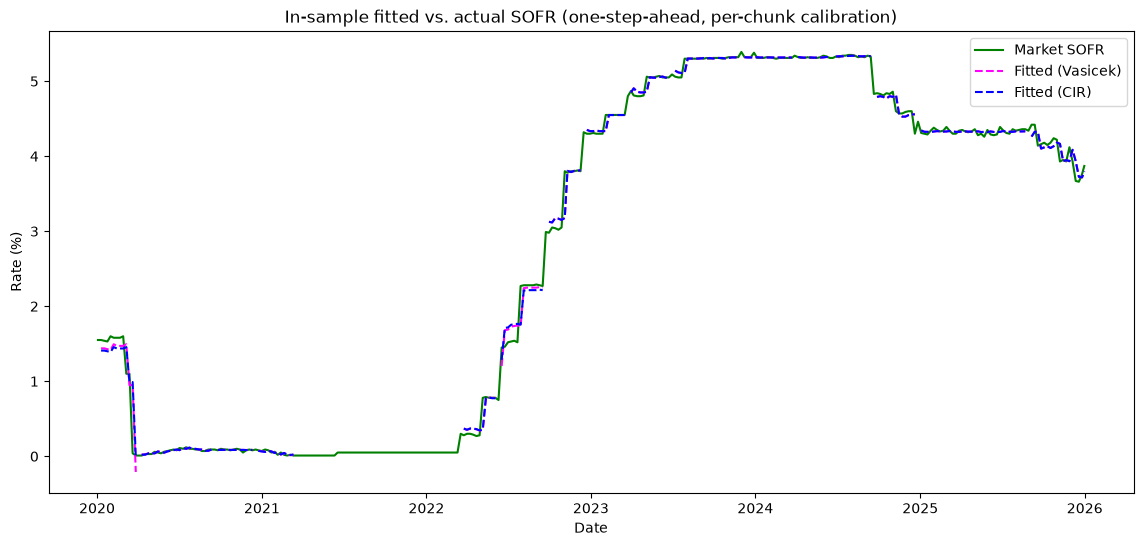

In [21]:
plt.figure(figsize=(14, 6))
plt.plot(df_norm.index, df_norm["sofr"], label="Market SOFR", color="green", linewidth=1.5)
plt.plot(df_norm.index, df_norm["fitted_vasicek"], label="Fitted (Vasicek)", color="magenta", linestyle="--")
plt.plot(df_norm.index, df_norm["fitted_cir"], label="Fitted (CIR)", color="blue", linestyle="--")
plt.title("In-sample fitted vs. actual SOFR (one-step-ahead, per-chunk calibration)")
plt.xlabel("Date")
plt.ylabel("Rate (%)")
plt.legend()
plt.show()

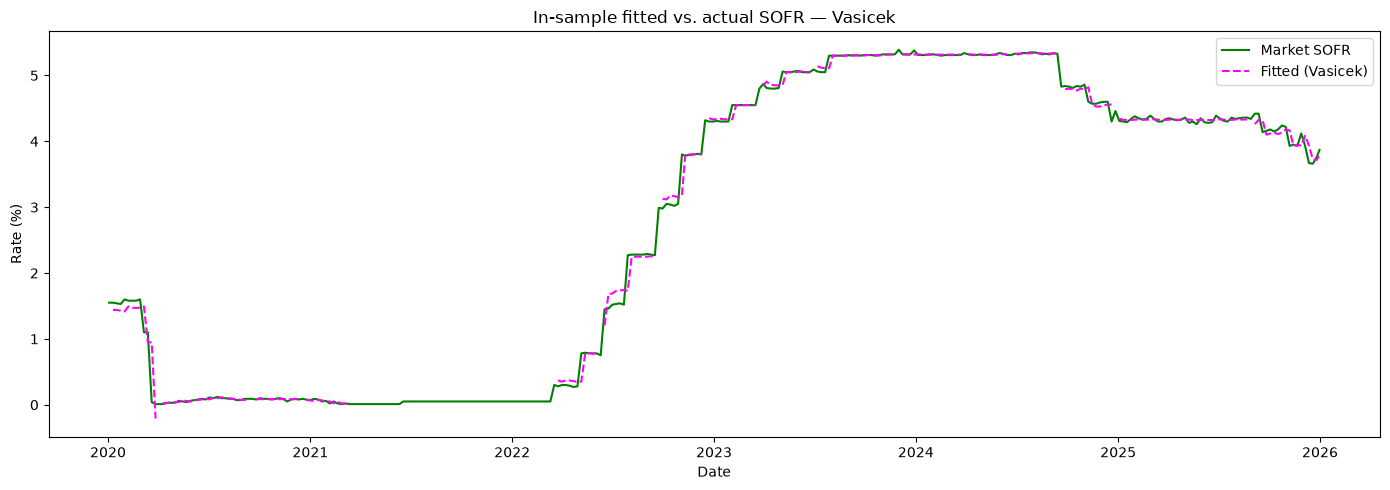

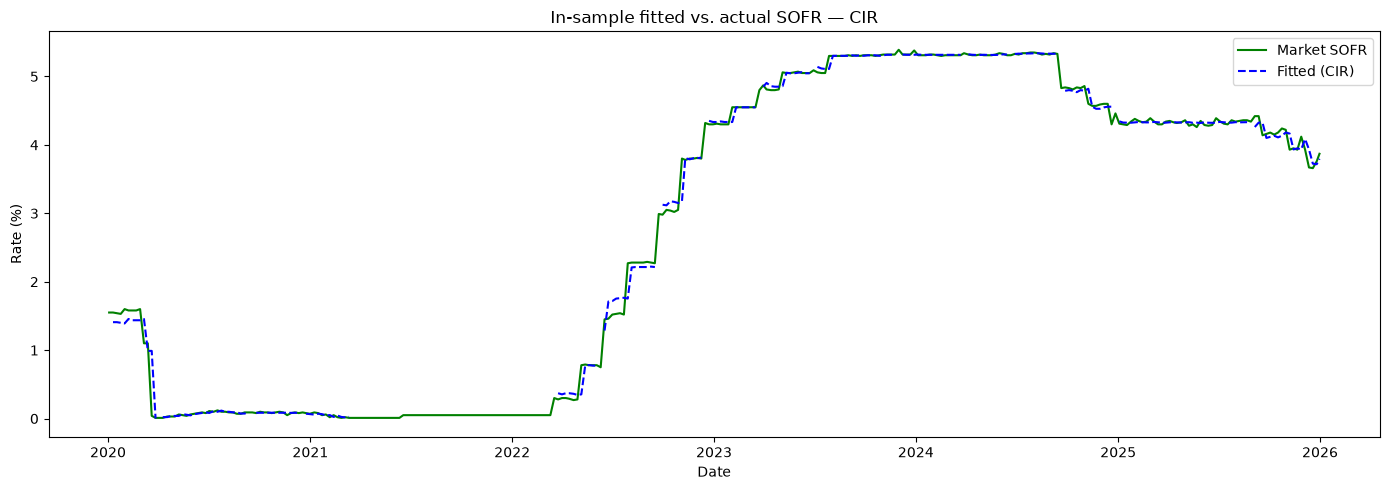

In [22]:
for model, color, name in [("vasicek", "magenta", "Vasicek"), ("cir", "blue", "CIR")]:
    plt.figure(figsize=(14, 5))
    plt.plot(df_norm.index, df_norm["sofr"], label="Market SOFR", color="green", linewidth=1.5)
    plt.plot(df_norm.index, df_norm[f"fitted_{model}"], label=f"Fitted ({name})", color=color, linestyle="--")
    plt.title(f"In-sample fitted vs. actual SOFR — {name}")
    plt.xlabel("Date")
    plt.ylabel("Rate (%)")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 5. Error analysis

Per-chunk RMSE $\varepsilon_k$ over the fitted points of chunk $k$, and the overall weighted RMSE
(paper eq. 9):

$$
\varepsilon_e = \sqrt{\sum_k \frac{n_k}{n}\,\varepsilon_k^2}.
$$

In [23]:
def compute_chunk_rmse(df, chunk_col="chunk_id", rate_col="sofr", model="vasicek"):
    """Adds residual column error_<model> and returns per-chunk RMSE (epsilon_k)."""
    fitted_col = f"fitted_{model}"
    df = df.copy()
    df[f"error_{model}"] = df[rate_col] - df[fitted_col]

    chunk_rmse = (
        df.dropna(subset=[fitted_col])
          .groupby(chunk_col)[f"error_{model}"]
          .apply(lambda e: np.sqrt(np.mean(e ** 2)))
          .rename(f"rmse_{model}")
          .reset_index()
    )
    return df, chunk_rmse


df_norm, rmse_vasicek = compute_chunk_rmse(df_norm, model="vasicek")
df_norm, rmse_cir = compute_chunk_rmse(df_norm, model="cir")

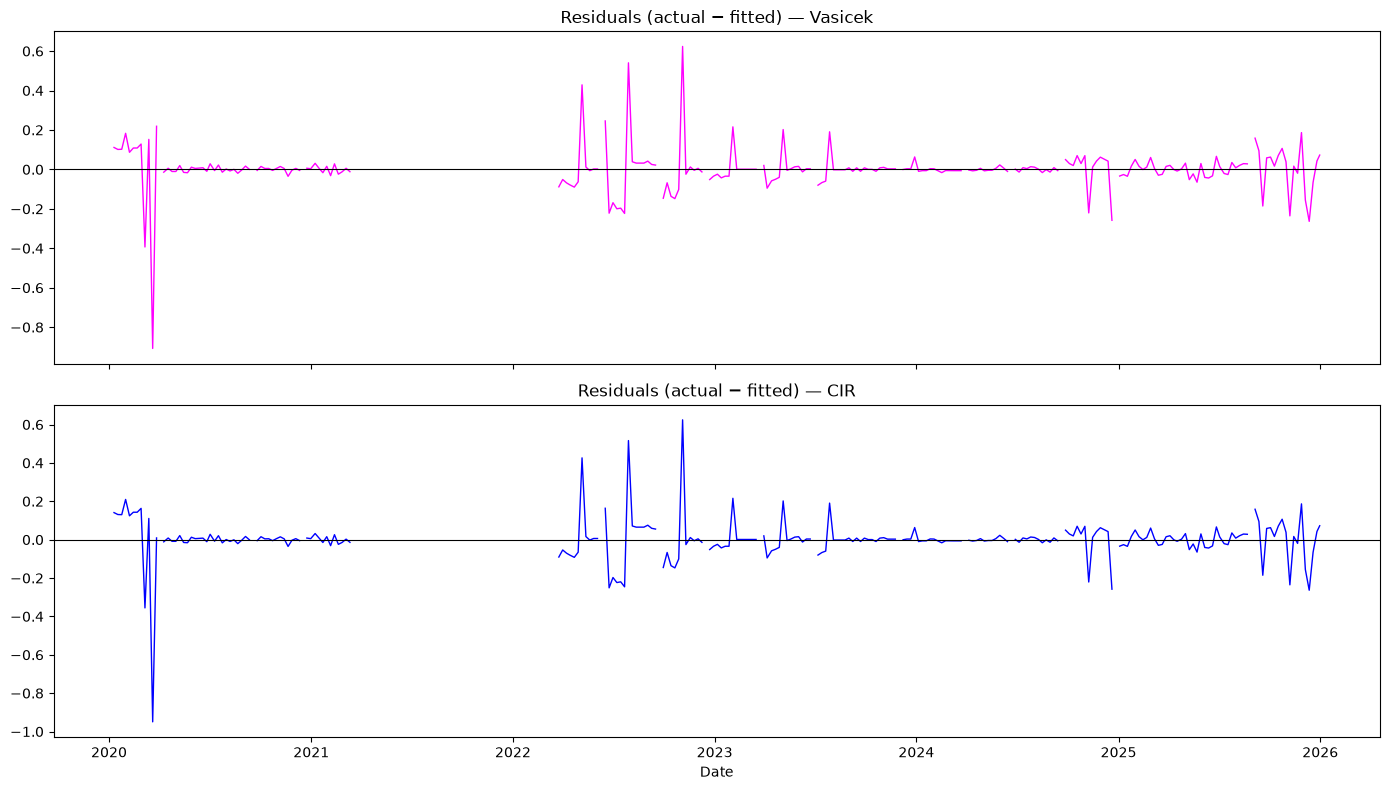

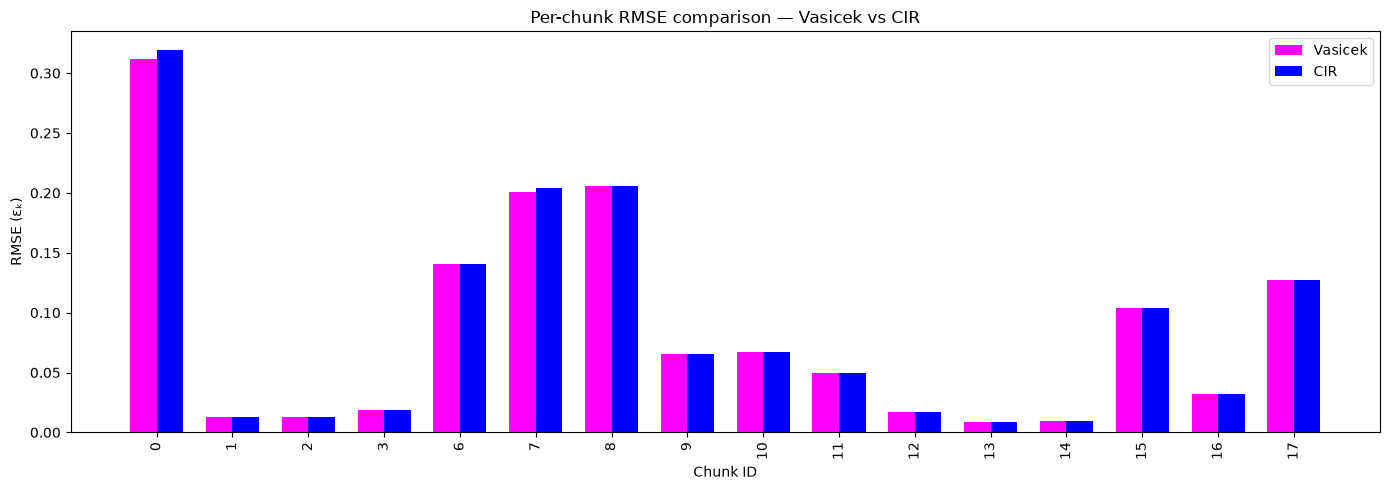

In [24]:
# Residuals over time
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, (model, color, name) in zip(axes, [("vasicek", "magenta", "Vasicek"), ("cir", "blue", "CIR")]):
    ax.plot(df_norm.index, df_norm[f"error_{model}"], color=color, linewidth=1)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"Residuals (actual − fitted) — {name}")
axes[1].set_xlabel("Date")
plt.tight_layout()
plt.show()

# Per-chunk RMSE, side by side
merged_rmse = pd.merge(rmse_vasicek, rmse_cir, on="chunk_id", how="outer").sort_values("chunk_id")
x, width = np.arange(len(merged_rmse)), 0.35

plt.figure(figsize=(14, 5))
plt.bar(x - width / 2, merged_rmse["rmse_vasicek"], width, label="Vasicek", color="magenta")
plt.bar(x + width / 2, merged_rmse["rmse_cir"], width, label="CIR", color="blue")
plt.xticks(x, merged_rmse["chunk_id"], rotation=90)
plt.xlabel("Chunk ID")
plt.ylabel("RMSE (εₖ)")
plt.title("Per-chunk RMSE comparison — Vasicek vs CIR")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
def compute_overall_rmse(chunk_rmse_df, calibration_df, model="vasicek"):
    """Weighted overall RMSE epsilon_e (paper eq. 9): sqrt(sum_k (n_k / n) * eps_k^2)."""
    merged = pd.merge(chunk_rmse_df, calibration_df[["chunk_id", "n_points"]], on="chunk_id", how="inner")
    weights = merged["n_points"] / merged["n_points"].sum()
    return np.sqrt(np.sum(weights * merged[f"rmse_{model}"] ** 2))


epsilon_e_vasicek = compute_overall_rmse(rmse_vasicek, calibrated_results, model="vasicek")
epsilon_e_cir = compute_overall_rmse(rmse_cir, calibrated_results, model="cir")

print(f"Overall weighted RMSE — Vasicek: {epsilon_e_vasicek:.4f}")
print(f"Overall weighted RMSE — CIR: {epsilon_e_cir:.4f}")

Overall weighted RMSE — Vasicek: 0.1122
Overall weighted RMSE — CIR: 0.1136


### Summary (normality partitioning)

| Model | Overall weighted RMSE $\varepsilon_e$ |
|---|---|
| **Vasicek** | **0.1122** |
| CIR | 0.1136 |

Under Lilliefors partitioning Vasicek edges out CIR on SOFR. The paper's headline comparison uses
non-central $\chi^2$ partitioning (the CIR transition density), which is the next section.

## 6. Partitioning by non-central chi-squared (work in progress)

Same forward-expanding scheme, but each window is tested against a **non-central $\chi^2$** distribution
(the CIR transition law): fit `ncx2` by MLE, then run a Kolmogorov–Smirnov test against the fitted law.

> **Status:** with all four `ncx2` parameters free (df, nc, loc, scale) the fit is flexible enough to pass
> the KS test on any window, so the whole sample collapses into **one chunk**. Next step: constrain the
> fit (`floc=0, fscale=1`) so the test has power, then rerun calibration and the Vasicek vs CIR comparison
> on these chunks.

In [26]:
def partition_by_ncx2(week_df, rate_col="sofr", min_points=4, alpha=0.05, std_threshold=0.01):
    """Forward-expanding partitioning with an MLE-fitted ncx2 + KS test on each window."""
    rates = week_df[rate_col].values
    n = len(rates)
    chunk_ids = np.full(n, -1, dtype=int)

    chunk_num, start = 0, 0
    while start < n:
        if n - start < min_points:
            break

        end = start + min_points
        last_good_end = None

        while end <= n:
            window = rates[start:end]

            if np.std(window) < std_threshold:
                passes = True  # near-degenerate (ZIRP) window -> keep growing
            else:
                try:
                    df_fit, nc_fit, loc_fit, scale_fit = stats.ncx2.fit(window)
                    _, p_value = stats.kstest(window, "ncx2", args=(df_fit, nc_fit, loc_fit, scale_fit))
                    passes = p_value >= alpha
                except Exception:
                    passes = True  # fit failed -> inconclusive, keep growing

            if passes:
                last_good_end = end
                end += 1
            else:
                break

        if last_good_end is None:
            last_good_end = start + min_points

        chunk_ids[start:last_good_end] = chunk_num
        chunk_num += 1
        start = last_good_end

    out = week_df.copy()
    out["chunk_id_ncx2"] = chunk_ids
    return out


df_ncx2 = partition_by_ncx2(week_df, rate_col="sofr")
print(df_ncx2["chunk_id_ncx2"].value_counts().sort_index())

chunk_id_ncx2
0    314
Name: count, dtype: int64


## References

- Orlando, G., Mininni, R. M., & Bufalo, M. (2020). Forecasting interest rates through Vasicek and CIR
  models: A partitioning approach. *Journal of Forecasting*, 39(4), 569–579.
  [arXiv:1901.02246](https://arxiv.org/abs/1901.02246)
- Bibby, B. M., Jacobsen, M., & Sørensen, M. (2010). Estimating functions for discretely sampled
  diffusion-type models. *Handbook of Financial Econometrics.*
- Federal Reserve Bank of St. Louis — FRED series [`SOFR`](https://fred.stlouisfed.org/series/SOFR).